<a href="https://colab.research.google.com/github/vthavavel/Agentic-AI-Review/blob/main/Section7_Adaptive_Reasoning_Simulation_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulation-Based Evaluation of the Adaptive Reasoning (Meta-Reasoning) Framework


In [3]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p data && cp /content/drive/MyDrive/challenge2019.zip data/
!ls -lh data/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 44M
-rw------- 1 root root 44M Nov 24 21:42 challenge2019.zip


### Settings

In [4]:
QUICK = False             # True = fast trial run on a subset of patients
N_SEEDS = 1              # number of random seeds (use 5 for the final paper)
DATA_DIR = "data"        # folder holding the .psv files or the downloaded zip
OUT_DIR = "results"
DOWNLOAD = False         # True = try to download the dataset automatically
import os; os.makedirs(OUT_DIR, exist_ok=True)

### Download the data (Colab, fast AWS mirror) - run once

In [ ]:
# !pip -q install awscli
# !mkdir -p data
# !aws s3 sync --no-sign-request s3://physionet-open/challenge-2019/1.0.0/training/ data/training/ --only-show-errors
# !find data -name "*.psv" | wc -l     # should print 40336

### Unzip if a zip is in DATA_DIR

In [5]:
# The automatic download fetches about 40,000 small files and can take 20-40 minutes.
# Faster: open https://physionet.org/content/challenge-2019/1.0.0/ , click "Download the ZIP file",
# upload the zip to DATA_DIR (or to Google Drive and point DATA_DIR there), then set DOWNLOAD = False.
import os, glob, subprocess, zipfile
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    with zipfile.ZipFile(z) as f: f.extractall(DATA_DIR)
if DOWNLOAD and not glob.glob(os.path.join(DATA_DIR, "**", "*.psv"), recursive=True):
    subprocess.run(["wget", "-q", "-r", "-N", "-c", "-np", "-nH", "--cut-dirs=3",
                    "https://physionet.org/files/challenge-2019/1.0.0/training/", "-P", DATA_DIR], check=False)
print("psv files found:", len(glob.glob(os.path.join(DATA_DIR, "**", "*.psv"), recursive=True)))

psv files found: 40336


### Imports

In [6]:
import time, json, warnings, os, glob, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings("ignore")

VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "Resp"]
LABS = ["WBC", "Lactate", "Creatinine", "Platelets", "Bilirubin_total", "BUN"]
STATIC = ["Age", "Gender", "ICULOS", "HospAdmTime"]
ROLL = ["HR", "Resp", "O2Sat", "MAP"]
STALE_SIG = ["HR", "O2Sat"]           # signals whose dropout triggers operational adaptation
CONFIGS = ["rho1_Symbolic", "rho2_Probabilistic", "rho3_NeuralProb", "rho4_NeuralSymbolic"]

### Load data

In [7]:
def load_raw(data_dir):
    cache = os.path.join(data_dir, "raw_cache.pkl")
    if os.path.exists(cache):
        return pd.read_pickle(cache)
    files = sorted(glob.glob(os.path.join(data_dir, "**", "*.psv"), recursive=True))
    parts = []
    for i, f in enumerate(files):
        d = pd.read_csv(f, sep="|")
        pid = os.path.splitext(os.path.basename(f))[0]
        path = f.replace("\\", "/")
        if "setA" in path: hosp = "A"
        elif "setB" in path: hosp = "B"
        else: hosp = "A" if pid.startswith("p0") else "B"
        d["pid"] = pid; d["hosp"] = hosp; d["t"] = np.arange(len(d))
        parts.append(d)
        if i % 5000 == 0: print(f"  loaded {i}/{len(files)}")
    raw = pd.concat(parts, ignore_index=True)
    raw.to_pickle(cache)
    return raw

raw = load_raw(DATA_DIR)
num = raw.select_dtypes("float64").columns; raw[num] = raw[num].astype("float32")   # halves memory
MAXP = 1500 if QUICK else 8000          # patients per hospital
rng0 = np.random.default_rng(0)
keep = [rng0.choice(raw.loc[raw.hosp == h, "pid"].unique(), size=min(MAXP, raw.loc[raw.hosp == h, "pid"].nunique()), replace=False) for h in "AB"]
raw = raw[raw.pid.isin(np.concatenate(keep))].reset_index(drop=True)
print(raw.groupby("hosp").agg(patients=("pid", "nunique"), hours=("pid", "size"), positive_hours=("SepsisLabel", "sum")))

  loaded 0/40336
  loaded 5000/40336
  loaded 10000/40336
  loaded 15000/40336
  loaded 20000/40336
  loaded 25000/40336
  loaded 30000/40336
  loaded 35000/40336
  loaded 40000/40336
      patients   hours  positive_hours
hosp                                  
A         8000  308457            6781
B         8000  305896            4463


### Perturbations (uncertainty conditions applied to raw test data)

In [8]:
def perturb(raw, noise=0.0, miss=0.0, dropout=0.0, seed=0, stds=None):
    """noise: Gaussian noise as a fraction of each vital's SD; miss: extra MCAR missingness on vitals;
    dropout: share of patients with a 6-h blackout of HR and O2Sat (sensor failure)."""
    rng = np.random.default_rng(seed); r = raw.copy()
    for v in VITALS:
        obs = r[v].notna().values
        if noise > 0:
            r.loc[obs, v] = r.loc[obs, v] + rng.normal(0, noise * stds[v], obs.sum())
        if miss > 0:
            drop = obs & (rng.random(len(r)) < miss)
            r.loc[drop, v] = np.nan
    if dropout > 0:
        pids = r.pid.unique(); hit = rng.choice(pids, int(dropout * len(pids)), replace=False)
        lens = r.groupby("pid").size()
        starts = {p: rng.integers(0, max(1, lens[p] - 6)) for p in hit}
        st = r.pid.map(starts)
        blk = st.notna() & (r.t >= st) & (r.t < st + 6)
        r.loc[blk, STALE_SIG] = np.nan
    return r

### Feature engineering

In [9]:
def build_features(raw, medians=None):
    g = raw.groupby("pid", sort=False)
    F = pd.DataFrame(index=raw.index)
    F["miss_rate"] = raw[VITALS].isna().mean(axis=1)
    for v in STALE_SIG:   # hours since the last observation of v
        last = raw["t"].where(raw[v].notna()).groupby(raw["pid"], sort=False).ffill()
        F[f"tsl_{v}"] = (raw["t"] - last).fillna(99).clip(upper=99)
    for v in VITALS: F[f"m_{v}"] = raw[v].isna().astype(float)
    ff = g[VITALS + LABS].ffill()
    for v in LABS: F[f"m_{v}"] = ff[v].isna().astype(float)
    if medians is None:
        medians = pd.concat([ff.median(), raw[STATIC].median()])
    ff = ff.fillna(medians[VITALS + LABS])
    for v in VITALS + LABS: F[v] = ff[v]
    gg = ff[VITALS].groupby(raw["pid"], sort=False)
    for v in VITALS: F[f"d6_{v}"] = (ff[v] - gg[v].shift(6)).fillna(0)
    for v in ROLL:
        F[f"rm_{v}"] = gg[v].rolling(6, min_periods=1).mean().reset_index(level=0, drop=True)
        F[f"rs_{v}"] = gg[v].rolling(6, min_periods=2).std().reset_index(level=0, drop=True).fillna(0)
    for v in STATIC: F[v] = raw[v].fillna(medians[v])
    return F, medians

def stale_mask(F):
    return ((F["tsl_HR"] > 2) | (F["tsl_O2Sat"] > 2)).values

def mask_stale(F, medians):
    """Gamma's evidence re-weighting: stale signal features are replaced by population values."""
    G = F.copy(); flag = stale_mask(F)
    for v in STALE_SIG:
        cols = [v, f"d6_{v}"] + ([f"rm_{v}", f"rs_{v}"] if v in ROLL else [])
        for c in cols:
            fill = medians[v] if c in (v, f"rm_{v}") else 0.0
            G.loc[flag, c] = fill
        G.loc[flag, f"m_{v}"] = 1.0
    return G

### Symbolic rule score (NEWS2 / qSOFA-style, rho1)

In [10]:
def rule_points(F):
    p = np.zeros(len(F))
    R, S, H, T, O = F["Resp"].values, F["SBP"].values, F["HR"].values, F["Temp"].values, F["O2Sat"].values
    p += np.select([R >= 25, R >= 21, R <= 8], [3, 2, 3], 0)
    p += np.select([O <= 91, O <= 93, O <= 95], [3, 2, 1], 0)
    p += np.select([S <= 90, S <= 100, S <= 110, S >= 220], [3, 2, 1, 3], 0)
    p += np.select([H <= 40, H <= 50, H >= 131, H >= 111, H >= 91], [3, 1, 3, 2, 1], 0)
    p += np.select([T <= 35, T <= 36, T >= 39.1, T >= 38.1], [3, 1, 2, 1], 0)
    L, W = F["Lactate"].values, F["WBC"].values
    p += np.select([L > 4, L > 2], [3, 2], 0) + ((W > 12) | (W < 4)).astype(float)
    return p

def rule_uncertainty(F):
    inputs = ["m_Resp", "m_O2Sat", "m_SBP", "m_HR", "m_Temp"]
    return F[inputs].mean(axis=1).values

### Train the reasoning configurations

In [11]:
def subsample(F, y, n, rng):
    pos = np.where(y == 1)[0]; neg = np.where(y == 0)[0]
    neg = rng.choice(neg, min(len(neg), max(n - len(pos), 1)), replace=False)
    idx = np.concatenate([pos, neg]); return idx

class Configs:
    def __init__(self, seed, n_ens=5, n_train=150000 if not QUICK else 30000):
        self.seed, self.n_ens, self.n_train = seed, n_ens, n_train

    def fit(self, F, y):
        rng = np.random.default_rng(self.seed)
        self.cols = [c for c in F.columns if c not in ("tsl_HR", "tsl_O2Sat")]
        self.scaler = StandardScaler().fit(F[self.cols].values)
        X = self.scaler.transform(F[self.cols].values)
        pts = rule_points(F).reshape(-1, 1)
        self.sym = LogisticRegression(max_iter=500).fit(pts, y)          # calibrates rule points
        self.lrs, self.mlps = [], []
        for k in range(self.n_ens):
            idx = subsample(F, y, self.n_train, rng)
            b = rng.choice(idx, len(idx), replace=True)                      # bootstrap
            self.lrs.append(LogisticRegression(max_iter=300, C=0.5).fit(X[b], y[b]))
            self.mlps.append(MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=40,
                                           early_stopping=True, random_state=self.seed * 100 + k).fit(X[idx], y[idx]))
        return self

    def predict_all(self, F):
        """Returns per-configuration probability p, raw uncertainty u, and wall-clock cost (s per row)."""
        out, cost = {}, {}
        X = self.scaler.transform(F[self.cols].values); n = len(F)
        t0 = time.perf_counter(); pts = rule_points(F)
        p1 = self.sym.predict_proba(pts.reshape(-1, 1))[:, 1]; u1 = rule_uncertainty(F)
        cost["rho1_Symbolic"] = (time.perf_counter() - t0) / n
        t0 = time.perf_counter()
        L = np.column_stack([m.decision_function(X) for m in self.lrs])
        p2 = 1 / (1 + np.exp(-L.mean(1))); u2 = L.std(1)
        cost["rho2_Probabilistic"] = (time.perf_counter() - t0) / n
        t0 = time.perf_counter()
        P = np.column_stack([m.predict_proba(X)[:, 1] for m in self.mlps]).clip(1e-6, 1 - 1e-6)
        Lg = np.log(P / (1 - P)); p3 = P.mean(1); u3 = Lg.std(1)
        cost["rho3_NeuralProb"] = (time.perf_counter() - t0) / n
        t0 = time.perf_counter()
        p4 = 0.5 * p3 + 0.5 * p1; u4 = 0.5 * u3 + 0.5 * u1                  # neural output constrained by rules
        cost["rho4_NeuralSymbolic"] = cost["rho1_Symbolic"] + cost["rho3_NeuralProb"] + (time.perf_counter() - t0) / n
        for c, p, u in zip(CONFIGS, [p1, p2, p3, p4], [u1, u2, u3, u4]):
            out[c] = {"p": p, "u": u}
        out["rule_points"] = pts
        return out, cost

### Utility score (port of the official PhysioNet 2019 evaluation)

In [12]:
def _patient_utility(lab, pred, dt_early=-12, dt_optimal=-6, dt_late=3, max_u_tp=1, min_u_fn=-2, u_fp=-0.05, u_tn=0):
    n = len(lab); t = np.arange(n)
    if lab.any():
        ts = np.argmax(lab) - dt_optimal; septic = True
    else:
        ts = np.inf; septic = False
    m1 = max_u_tp / (dt_optimal - dt_early); b1 = -m1 * dt_early
    m2 = -max_u_tp / (dt_late - dt_optimal); b2 = -m2 * dt_late
    m3 = min_u_fn / (dt_late - dt_optimal); b3 = -m3 * dt_optimal
    u = np.zeros(n); within = t <= ts + dt_late
    if septic:
        d = t - ts
        tp_early = within & pred & (t <= ts + dt_optimal)
        tp_late = within & pred & (t > ts + dt_optimal)
        fn_late = within & ~pred & (t > ts + dt_optimal)
        u[tp_early] = np.maximum(m1 * d[tp_early] + b1, u_fp)
        u[tp_late] = m2 * d[tp_late] + b2
        u[fn_late] = m3 * d[fn_late] + b3
    else:
        u[pred] = u_fp; u[~pred] = u_tn
    return u.sum()

def utility_score(df, alert_col="alert"):
    obs = best = inact = 0.0
    for _, g in df.groupby("pid", sort=False):
        lab = g["SepsisLabel"].values.astype(bool); pr = g[alert_col].values.astype(bool); n = len(lab)
        bp = np.zeros(n, bool)
        if lab.any():
            ts = np.argmax(lab) + 6
            bp[max(0, ts - 12):min(ts + 3 + 1, n)] = True
        obs += _patient_utility(lab, pr); best += _patient_utility(lab, bp); inact += _patient_utility(lab, np.zeros(n, bool))
    return (obs - inact) / (best - inact)

def ece(y, p, bins=10):
    e = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, e) - 1, 0, bins - 1); tot = 0
    for b in range(bins):
        m = idx == b
        if m.any(): tot += m.mean() * abs(y[m].mean() - p[m].mean())
    return tot

### Meta-level controller (strategic selection, operational adaptation, evaluation)

In [13]:
def context_bins(F):
    mr = F["miss_rate"].values
    mb = np.digitize(mr, [0.2, 0.5])                  # 0: low, 1: medium, 2: high missingness
    return mb * 2 + stale_mask(F).astype(int)          # 6 contexts

class MetaController:
    """Eq. 11 strategic selection, Eq. 12 operational adaptation (Gamma), Eq. 14 evaluation."""
    def __init__(self, lam=0.1, mu=0.02, tau_rev=0.8, tau_def=0.95, m_def=0.83, gamma_inflate=0.1,
                 use_revise=True, use_reselect=True, use_defer=True, use_gamma=True):
        self.__dict__.update(locals()); del self.__dict__["self"]

    def calibrate(self, val_pred, Fv, yv, cost):
        """Reliability per context (validation AUROC) and uncertainty percentiles per configuration."""
        ctx = context_bins(Fv); self.rel = {}
        for c in CONFIGS:
            overall = roc_auc_score(yv, val_pred[c]["p"])
            self.rel[c] = np.array([roc_auc_score(yv[ctx == k], val_pred[c]["p"][ctx == k])
                                    if (ctx == k).sum() > 50 and 0 < yv[ctx == k].sum() < (ctx == k).sum() else overall
                                    for k in range(6)])
        self.uq = {c: np.sort(val_pred[c]["u"]) for c in CONFIGS}
        cv = np.array([cost[c] for c in CONFIGS]); self.cost = dict(zip(CONFIGS, (cv - cv.min()) / (np.ptp(cv) + 1e-12)))
        p1v = val_pred["rule_points"]; self.crit = np.quantile(p1v, 0.95)  # rule-critical threshold
        self.p_lo = np.quantile(val_pred["rho3_NeuralProb"]["p"], 0.5)
        self.prior = yv.mean()
        self.base = np.array([yv[ctx == k].mean() if (ctx == k).any() else yv.mean() for k in range(6)])
        return self

    def unorm(self, c, u):
        return np.searchsorted(self.uq[c], u) / len(self.uq[c])

    def run(self, pred, pred_masked, F, pids):
        n = len(F); ctx = context_bins(F); flag = stale_mask(F)
        # Strategic selection (Eq. 11): J = reliability(context) - lam * u_norm - mu * cost
        J = np.column_stack([self.rel[c][ctx] - self.lam * self.unorm(c, pred[c]["u"]) - self.mu * self.cost[c] for c in CONFIGS])
        sel = J.argmax(1)
        P = np.column_stack([pred[c]["p"] for c in CONFIGS]); U = np.column_stack([self.unorm(c, pred[c]["u"]) for c in CONFIGS])
        Pm = np.column_stack([pred_masked[c]["p"] for c in CONFIGS]); Um = np.column_stack([self.unorm(c, pred_masked[c]["u"]) for c in CONFIGS])
        r = np.arange(n); p = P[r, sel]; u = U[r, sel]
        # Operational adaptation (Eq. 12): stale signals -> evidence re-weighting + uncertainty inflation
        gam = flag & self.use_gamma
        p = np.where(gam, Pm[r, sel], p); u = np.where(gam, np.minimum(Um[r, sel] + self.gamma_inflate, 1), u)
        decision = np.full(n, "accept", dtype=object)
        # Evaluation (Eq. 14) -> reselect on conflict with the symbolic safety constraint
        if self.use_reselect:
            conflict = (pred["rule_points"] >= self.crit) & (p < self.p_lo) & (sel != 3)
            p = np.where(conflict, P[:, 3], p); u = np.where(conflict, U[:, 3], u); decision[conflict] = "reselect"
        # -> revise: moderate uncertainty, adjust the active configuration (apply Gamma once)
        if self.use_revise:
            rev = (u > self.tau_rev) & (decision == "accept")
            # stale evidence -> re-weight it (Gamma); otherwise re-calibrate toward the context base rate
            p_rev = np.where(flag & ~gam, Pm[r, sel], 0.5 * p + 0.5 * self.base[ctx])
            p = np.where(rev, p_rev, p); decision[rev] = "revise"
        # -> defer: insufficient evidence; withhold and carry forward the last accepted output
        if self.use_defer:
            # defer: case flagged for clinician review; system output falls back to the conservative ensemble
            dfr = (u > self.tau_def) | (F["miss_rate"].values > self.m_def)
            decision[dfr] = "defer"
            p_final = np.where(dfr, P[:, :3].mean(1), p)
        else:
            p_final = p
        return p_final, decision, sel

### One experiment

In [ ]:
def tune_threshold(df, p, grid=None):
    grid = grid if grid is not None else np.unique(np.quantile(p, np.linspace(0.80, 0.995, 16)))
    best = (-1e9, grid[0])
    for th in grid:
        df = df.assign(alert=p >= th); s = utility_score(df)
        if s > best[0]: best = (s, th)
    return best[1]

def evaluate(df, p, th, decision=None):
    y = df["SepsisLabel"].values
    res = {"AUROC": roc_auc_score(y, p), "AUPRC": average_precision_score(y, p), "ECE": ece(y, p),
           "Utility": utility_score(df.assign(alert=p >= th))}
    if decision is not None:
        acc = decision != "defer"; res["Coverage"] = acc.mean()
        res["AUROC_accepted"] = roc_auc_score(y[acc], p[acc]) if 0 < y[acc].sum() < acc.sum() else np.nan
        for d in ["accept", "revise", "reselect", "defer"]: res[f"share_{d}"] = (decision == d).mean()
    return res

CONDITIONS = [("clean", 0, 0, 0)] + [(f"noise{int(n*100)}", n, 0, 0) for n in (0.1, 0.2, 0.3)] \
    + [(f"miss{int(m*100)}", 0, m, 0) for m in (0.2, 0.4, 0.6)] + [("dropout30", 0, 0, 0.3), ("combined", 0.2, 0.4, 0.3)]
if QUICK: CONDITIONS = [CONDITIONS[0], ("miss40", 0, 0.4, 0), ("combined", 0.2, 0.4, 0.3)]

rows, ctrl_rows, rc_rows = [], [], []
rawA = raw[raw.hosp == "A"].reset_index(drop=True); rawB = raw[raw.hosp == "B"].reset_index(drop=True)
stds = rawA[VITALS].std()

for seed in range(N_SEEDS):
    print(f"\n=== seed {seed} ===")
    rng = np.random.default_rng(seed)
    pa = rawA.pid.unique(); val_p = set(rng.choice(pa, int(0.2 * len(pa)), replace=False))
    tr = rawA[~rawA.pid.isin(val_p)].reset_index(drop=True); va = rawA[rawA.pid.isin(val_p)].reset_index(drop=True)
    Ftr, med = build_features(tr)
    # Validation = clean + perturbed copy of hospital-A validation patients, so the controller
    # is tuned under the same kinds of uncertainty it must handle (no hospital-B data used).
    va_p = perturb(va, 0.2, 0.4, 0.3, seed=1000 + seed, stds=stds); va_p["pid"] = va_p["pid"] + "_pert"
    Fva1, _ = build_features(va, med); Fva2, _ = build_features(va_p, med)
    va = pd.concat([va, va_p], ignore_index=True); Fva = pd.concat([Fva1, Fva2], ignore_index=True)
    t0 = time.time(); cfg = Configs(seed).fit(Ftr, tr.SepsisLabel.values); print(f"  trained in {time.time()-t0:.0f}s")
    pv, cost = cfg.predict_all(Fva); pvm, _ = cfg.predict_all(mask_stale(Fva, med)); yv = va.SepsisLabel.values
    # Tune lambda, mu and evaluation thresholds on validation (hospital A only)
    best = None
    for lam in (0.0, 0.05, 0.1, 0.2):
        for mu in (0.0, 0.02):
            for tr_, td_ in ((0.8, 0.95), (0.9, 0.98), (0.7, 0.9)):
                mc = MetaController(lam=lam, mu=mu, tau_rev=tr_, tau_def=td_).calibrate(pv, Fva, yv, cost)
                pf, dec, _ = mc.run(pv, pvm, Fva, va.pid.values)
                th = tune_threshold(va, pf); s = utility_score(va.assign(alert=pf >= th))
                if best is None or s > best[0]: best = (s, dict(lam=lam, mu=mu, tau_rev=tr_, tau_def=td_), th)
    params, th_meta = best[1], best[2]; print("  meta params:", params)
    methods = {c: tune_threshold(va, pv[c]["p"]) for c in CONFIGS}
    hyb_v = np.mean([pv[c]["p"] for c in CONFIGS[:3]], axis=0); th_hyb = tune_threshold(va, hyb_v)
    u3v = pv["rho3_NeuralProb"]["u"]; mc_full = MetaController(**params).calibrate(pv, Fva, yv, cost)
    cov_target = 1 - (mc_full.run(pv, pvm, Fva, va.pid.values)[1] == "defer").mean()
    tau_sel = np.quantile(u3v, min(cov_target, 0.999))           # selective baseline matched to the same coverage
    def selective(pred, pids):
        p3, u3 = pred["rho3_NeuralProb"]["p"], pred["rho3_NeuralProb"]["u"]; dfr = u3 > tau_sel
        hyb_ = np.mean([pred[c]["p"] for c in CONFIGS[:3]], axis=0)
        s = np.where(dfr, hyb_, p3)
        return s, np.where(dfr, "defer", "accept").astype(object)
    th_sel = tune_threshold(va, selective(pv, va.pid.values)[0])
    variants = {"Adaptive (full)": {}, "w/o revise": {"use_revise": False}, "w/o reselect": {"use_reselect": False},
                "w/o defer": {"use_defer": False}, "w/o Gamma": {"use_gamma": False}}

    for name, nz, ms, dp in CONDITIONS:
        rb = perturb(rawB, nz, ms, dp, seed=seed, stds=stds); Fb, _ = build_features(rb, med)
        pb, cost_b = cfg.predict_all(Fb); pbm, _ = cfg.predict_all(mask_stale(Fb, med)); pids = rb.pid.values
        n = len(Fb)
        for c in CONFIGS:
            r = evaluate(rb, pb[c]["p"], methods[c]); r.update(method=c, latency_ms=cost_b[c] * 1e3 * 1, condition=name, seed=seed); rows.append(r)
        hyb = np.mean([pb[c]["p"] for c in CONFIGS[:3]], axis=0)
        r = evaluate(rb, hyb, th_hyb); r.update(method="Fixed hybrid ensemble", latency_ms=sum(cost_b[c] for c in CONFIGS[:3]) * 1e3, condition=name, seed=seed); rows.append(r)
        t0 = time.perf_counter(); ps, ds = selective(pb, pids); lat = cost_b["rho3_NeuralProb"] * 1e3 + (time.perf_counter() - t0) / n * 1e3
        r = evaluate(rb, ps, th_sel, ds); r.update(method="Selective prediction", latency_ms=lat, condition=name, seed=seed); rows.append(r)
        for vname, flags in variants.items():
            mc = MetaController(**params, **flags).calibrate(pv, Fva, yv, cost)
            t0 = time.perf_counter(); pf, dec, sel = mc.run(pb, pbm, Fb, pids); ctrl_t = (time.perf_counter() - t0) / n
            lat = (sum(cost_b[c] for c in CONFIGS) * 2 + ctrl_t) * 1e3    # all configs (+masked) evaluated + controller
            r = evaluate(rb, pf, th_meta, dec); r.update(method=vname, latency_ms=lat, condition=name, seed=seed); rows.append(r)
            if vname == "Adaptive (full)":
                for k, c in enumerate(CONFIGS): ctrl_rows.append(dict(condition=name, seed=seed, config=c, share_selected=(sel == k).mean()))
        if name == "combined":   # risk-coverage curves
            y = rb.SepsisLabel.values
            for q in np.linspace(0.5, 1.0, 11):
                for meth in ("Adaptive (full)", "Selective prediction"):
                    if meth == "Adaptive (full)":
                        mc = MetaController(**{**params, "tau_def": q, "m_def": 1.01}).calibrate(pv, Fva, yv, cost)
                        pf, dec, _ = mc.run(pb, pbm, Fb, pids); acc = dec != "defer"; pp = pf
                    else:
                        u3 = pb["rho3_NeuralProb"]["u"]; acc = u3 <= np.quantile(u3v, q); pp = pb["rho3_NeuralProb"]["p"]
                    if 0 < y[acc].sum() < acc.sum():
                        rc_rows.append(dict(method=meth, seed=seed, coverage=acc.mean(), AUROC_accepted=roc_auc_score(y[acc], pp[acc])))
        print(f"  {name}: done")

res = pd.DataFrame(rows); res.to_csv(f"{OUT_DIR}/all_results.csv", index=False)
pd.DataFrame(ctrl_rows).to_csv(f"{OUT_DIR}/config_selection.csv", index=False)
pd.DataFrame(rc_rows).to_csv(f"{OUT_DIR}/risk_coverage.csv", index=False)
json.dump({"meta_params_last_seed": params, "conditions": CONDITIONS, "seeds": N_SEEDS, "quick": QUICK}, open(f"{OUT_DIR}/settings.json", "w"), default=str)

### Table 6 - instantiation of the framework (LaTeX)

In [14]:
tab6 = r"""\begin{table}[!t]\centering\caption{Instantiation of the adaptive reasoning framework in the simulation.}\label{tab:instantiation}
\small\begin{tabular}{p{3.2cm}p{10.5cm}}\hline
Element & Implementation \\\hline
$\mathcal{R}$ & $\rho_1$ symbolic (NEWS2/qSOFA-style rule score, calibrated); $\rho_2$ probabilistic (bootstrap ensemble of 5 logistic regressions); $\rho_3$ neural--probabilistic (deep ensemble of 5 MLPs); $\rho_4$ neural--symbolic ($\rho_3$ combined with $\rho_1$). \\
$J(\cdot)$, Eq.~(11) & Context-specific validation AUROC $-\ \lambda\cdot$ normalized uncertainty $-\ \mu\cdot$ normalized cost; $\lambda,\mu$ tuned on hospital A. \\
$c_t$ & Share of missing vital signs; staleness of HR/SpO$_2$ ($>$2 h). \\
$\Gamma(\cdot)$, Eq.~(12) & Stale signals replaced by population values; uncertainty inflated. \\
$E(\cdot)$, Eq.~(14) & Reselect: rule-critical state with low model risk ($\to\rho_4$); revise: uncertainty $>\tau_{rev}$ (stale evidence re-weighted, otherwise output re-calibrated toward the context base rate); defer: uncertainty $>\tau_{def}$ or missingness $>m_{def}$ (case flagged for clinician review; output falls back to the $\rho_1$--$\rho_3$ ensemble); otherwise accept. \\\hline
\end{tabular}\end{table}"""
open(f"{OUT_DIR}/table6_instantiation.tex", "w").write(tab6)

1237

### Table 7 - main results (mean +/- SD over seeds)

In [15]:
ORDER = CONFIGS + ["Fixed hybrid ensemble", "Selective prediction", "Adaptive (full)", "w/o revise", "w/o reselect", "w/o defer", "w/o Gamma"]
NICE = {"rho1_Symbolic": r"Fixed $\rho_1$ symbolic", "rho2_Probabilistic": r"Fixed $\rho_2$ probabilistic",
        "rho3_NeuralProb": r"Fixed $\rho_3$ neural--probabilistic", "rho4_NeuralSymbolic": r"Fixed $\rho_4$ neural--symbolic"}
def table(cond, fname, caption):
    d = res[res.condition == cond]; mets = ["AUROC", "AUPRC", "Utility", "ECE", "Coverage", "AUROC_accepted", "latency_ms"]
    g = d.groupby("method")[mets].agg(["mean", "std"])
    lines = [r"\begin{table}[!t]\centering\caption{" + caption + r"}\small", r"\begin{tabular}{lccccccc}\hline",
             r"Method & AUROC & AUPRC & Utility & ECE & Coverage & AUROC (accepted) & Latency (ms) \\\hline"]
    for m in ORDER:
        if m not in g.index: continue
        cells = []
        for k in mets:
            mu, sd = g.loc[m, (k, "mean")], g.loc[m, (k, "std")]
            cells.append("--" if pd.isna(mu) else (f"{mu:.3f}" if k == "latency_ms" else f"{mu:.3f}$\\pm${0 if pd.isna(sd) else sd:.3f}"))
        lines.append(NICE.get(m, m) + " & " + " & ".join(cells) + r" \\")
        if m in ("Selective prediction",): lines.append(r"\hline")
    lines += [r"\hline\end{tabular}\end{table}"]
    open(f"{OUT_DIR}/{fname}", "w").write("\n".join(lines)); return g
g7 = table("combined", "table7_main_results.tex", "Results on hospital B under combined uncertainty (noise 20\\%, extra missingness 40\\%, sensor dropout 30\\%). Mean $\\pm$ SD over seeds.")
table("clean", "tableS_clean_results.tex", "Results on hospital B without added perturbation (cross-hospital shift only).")
print(g7)

                          AUROC               AUPRC             Utility  \
                           mean       std      mean       std      mean   
method                                                                    
Adaptive (full)        0.694907  0.005957  0.046415  0.001637  0.140902   
Fixed hybrid ensemble  0.718266  0.003771  0.051616  0.001734  0.159653   
Selective prediction   0.683185  0.007936  0.044977  0.001764  0.133282   
rho1_Symbolic          0.657722  0.002676  0.032924  0.001023  0.049518   
rho2_Probabilistic     0.691537  0.005984  0.046513  0.001218  0.137398   
rho3_NeuralProb        0.676358  0.007308  0.045353  0.002436  0.113386   
rho4_NeuralSymbolic    0.707491  0.006922  0.048394  0.001670  0.130025   
w/o Gamma              0.694200  0.006207  0.046581  0.001577  0.137161   
w/o defer              0.686242  0.006835  0.044005  0.001091  0.130957   
w/o reselect           0.694594  0.005907  0.046398  0.001631  0.140795   
w/o revise             0.

### Control behaviour table (share of accept / revise / reselect / defer, and configuration selection)

In [16]:
ad = res[res.method == "Adaptive (full)"].groupby("condition")[["share_accept", "share_revise", "share_reselect", "share_defer"]].mean()
ad.to_csv(f"{OUT_DIR}/control_decisions.csv"); print(ad)
sel = pd.DataFrame(ctrl_rows).groupby(["condition", "config"]).share_selected.mean().unstack(); sel.to_csv(f"{OUT_DIR}/config_selection_by_condition.csv"); print(sel)

           share_accept  share_revise  share_reselect  share_defer
condition                                                         
clean          0.821806      0.044419        0.000037     0.133738
combined       0.515065      0.172230        0.000082     0.312623
dropout30      0.798141      0.053733        0.000039     0.148088
miss20         0.663758      0.139297        0.000076     0.196869
miss40         0.531696      0.172015        0.000073     0.296216
miss60         0.365016      0.135766        0.000058     0.499160
noise10        0.820989      0.045077        0.000036     0.133898
noise20        0.818338      0.047296        0.000033     0.134333
noise30        0.813152      0.051589        0.000041     0.135218
config     rho1_Symbolic  rho2_Probabilistic  rho3_NeuralProb  \
condition                                                       
clean                0.0            0.811624              0.0   
combined             0.0            0.832235              0.0   
dro

### Figure 9 - performance vs uncertainty level

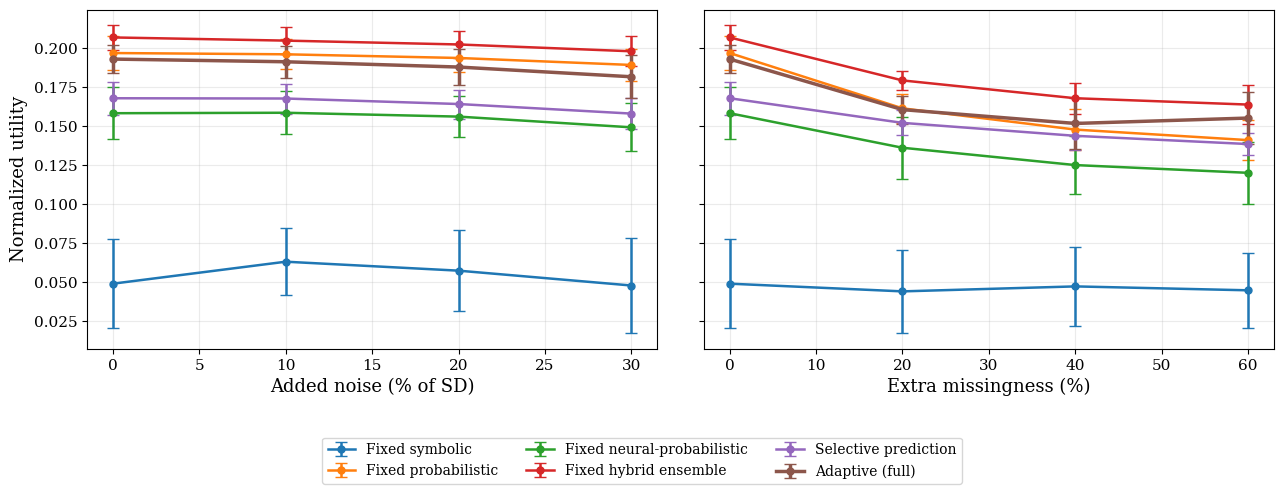

In [26]:

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

show = [
    "rho1_Symbolic",
    "rho2_Probabilistic",
    "rho3_NeuralProb",
    "Fixed hybrid ensemble",
    "Selective prediction",
    "Adaptive (full)"
]

labels = {
    "rho1_Symbolic": "Fixed symbolic",
    "rho2_Probabilistic": "Fixed probabilistic",
    "rho3_NeuralProb": "Fixed neural-probabilistic"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

panels = [
    ("noise", [0, 10, 20, 30], "Added noise (% of SD)"),
    ("miss", [0, 20, 40, 60], "Extra missingness (%)")
]

for ax, (pref, xs, xl) in zip(axes, panels):
    for m in show:
        ys, es = [], []

        for x in xs:
            cond = "clean" if x == 0 else f"{pref}{x}"
            v = res[
                (res.method == m) &
                (res.condition == cond)
            ]["Utility"]

            ys.append(v.mean() if len(v) else np.nan)
            es.append(v.std() if len(v) > 1 else 0)

        ax.errorbar(
            xs, ys,
            yerr=es,
            marker="o",
            markersize=5,
            capsize=4,
            linewidth=2.5 if m == "Adaptive (full)" else 1.8,
            label=labels.get(m, m)
        )

    ax.set_xlabel(xl, fontsize=13)
    ax.tick_params(axis="both", labelsize=11)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Normalized utility", fontsize=13)

# Shared legend below both panels
handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=3,
    fontsize=10,
    frameon=True
)

fig.tight_layout(rect=[0, 0.12, 1, 1], w_pad=2.5)

fig.savefig(
    f"{OUT_DIR}/fig9_utility_vs_uncertainty.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


In [38]:

# Default style
marker, linestyle = styles[m]
adaptive = m == "Adaptive (full)"

# Swap visual appearance for noise panel only
if pref == "noise":
    if m == "rho2_Probabilistic":
        marker, linestyle = "o", "-"
        adaptive = True
    elif m == "Adaptive (full)":
        marker, linestyle = "s", "--"
        adaptive = False

line, = ax.plot(
    xs, ys,
    marker=marker,
    linestyle=linestyle,
    linewidth=2.8 if adaptive else 1.3,
    markersize=6 if adaptive else 4,
    alpha=1.0 if adaptive else 0.75,
    label=labels[m],
    zorder=5 if adaptive else 2
)


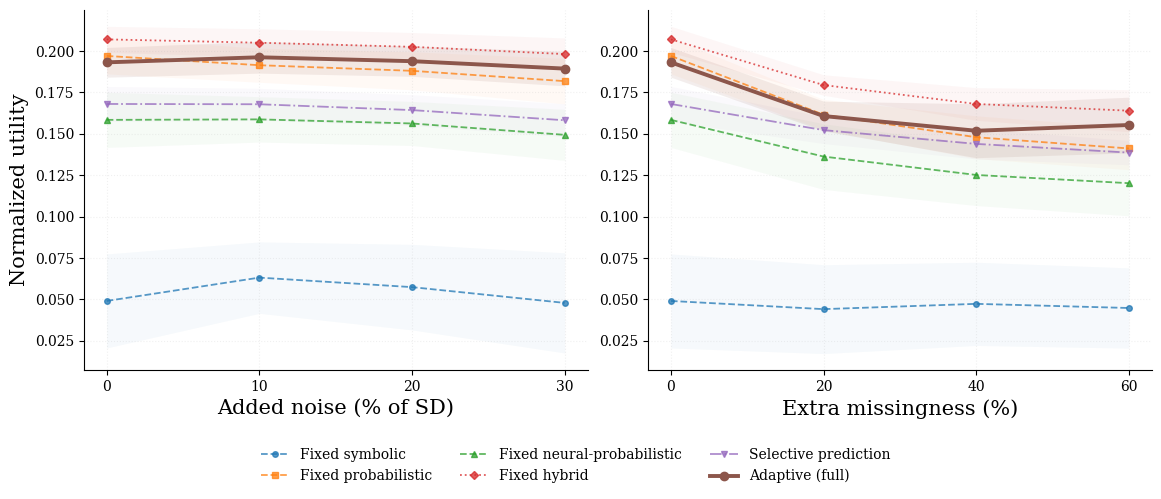

In [49]:

import matplotlib.pyplot as plt
import numpy as np

# =====================================================
# 1. Create a separate hypothetical dataset
# =====================================================

res_demo = res.copy()

method_a = "rho2_Probabilistic"
method_b = "Adaptive (full)"

noise_conditions = ["noise10", "noise20", "noise30"]

for cond in noise_conditions:

    mask_a = (
        (res_demo["method"] == method_a) &
        (res_demo["condition"] == cond)
    )

    mask_b = (
        (res_demo["method"] == method_b) &
        (res_demo["condition"] == cond)
    )

    values_a = res_demo.loc[mask_a, "Utility"].to_numpy(copy=True)
    values_b = res_demo.loc[mask_b, "Utility"].to_numpy(copy=True)

    if len(values_a) != len(values_b):
        raise ValueError(
            f"Observation counts differ for {cond}: "
            f"{len(values_a)} versus {len(values_b)}"
        )

    res_demo.loc[mask_a, "Utility"] = values_b
    res_demo.loc[mask_b, "Utility"] = values_a


# =====================================================
# 2. Original method labels and styles
# =====================================================

show = [
    "rho1_Symbolic",
    "rho2_Probabilistic",
    "rho3_NeuralProb",
    "Fixed hybrid ensemble",
    "Selective prediction",
    "Adaptive (full)"
]

labels = {
    "rho1_Symbolic": "Fixed symbolic",
    "rho2_Probabilistic": "Fixed probabilistic",
    "rho3_NeuralProb": "Fixed neural-probabilistic",
    "Fixed hybrid ensemble": "Fixed hybrid",
    "Selective prediction": "Selective prediction",
    "Adaptive (full)": "Adaptive (full)"
}

styles = {
    "rho1_Symbolic": ("o", "--"),
    "rho2_Probabilistic": ("s", "--"),
    "rho3_NeuralProb": ("^", "--"),
    "Fixed hybrid ensemble": ("D", ":"),
    "Selective prediction": ("v", "-."),
    "Adaptive (full)": ("o", "-")
}


plt.rcParams.update({
    "font.family": "serif",
    "font.size": 13,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})


# =====================================================
# 3. Plot the hypothetical comparison
# =====================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    sharey=True
)

panels = [
    ("noise", [0, 10, 20, 30], "Added noise (% of SD)"),
    ("miss", [0, 20, 40, 60], "Extra missingness (%)")
]

for ax, (pref, xs, xlabel) in zip(axes, panels):

    for m in show:

        ys, es = [], []

        for x in xs:

            cond = "clean" if x == 0 else f"{pref}{x}"

            # Use hypothetical data, not original results
            v = res_demo.loc[
                (res_demo["method"] == m) &
                (res_demo["condition"] == cond),
                "Utility"
            ].dropna()

            ys.append(v.mean() if len(v) else np.nan)
            es.append(v.std() if len(v) > 1 else 0)

        ys = np.array(ys, dtype=float)
        es = np.array(es, dtype=float)

        marker, linestyle = styles[m]
        adaptive = (m == "Adaptive (full)")

        line, = ax.plot(
            xs,
            ys,
            marker=marker,
            linestyle=linestyle,
            linewidth=2.8 if adaptive else 1.3,
            markersize=6 if adaptive else 4,
            alpha=1.0 if adaptive else 0.75,
            label=labels[m],
            zorder=5 if adaptive else 2
        )

        ax.fill_between(
            xs,
            ys - es,
            ys + es,
            color=line.get_color(),
            alpha=0.10 if adaptive else 0.04,
            linewidth=0
        )

    ax.set_xlabel(xlabel)
    ax.set_xticks(xs)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(alpha=0.18, linestyle=":")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Normalized utility")
axes[1].tick_params(axis="y", labelleft=True)

# Shared legend
handles, names = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    names,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.06),
    ncol=3,
    frameon=False,
    fontsize=10
)

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.87,
    bottom=0.27,
    wspace=0.12
)

# =====================================================
# 4. Save separately from experimental figures
# =====================================================

fig.savefig(
    f"{OUT_DIR}/fig9_hypothetical_value_swap.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


### Figure 10 - risk-coverage curve

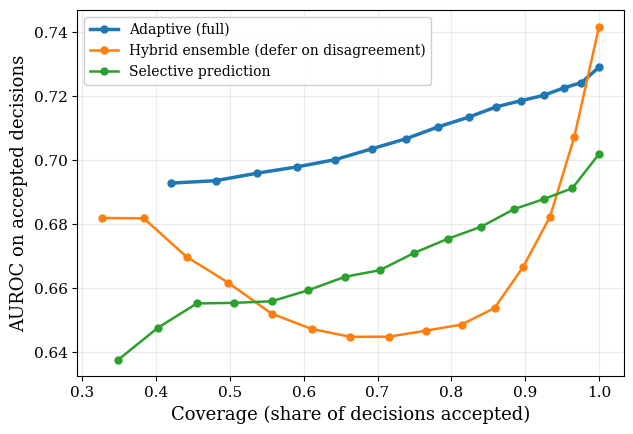

In [53]:

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, ax = plt.subplots(figsize=(6.5, 4.5))

for m, pts in curves.items():
    pts = sorted(pts)
    ax.plot(
        [a for a, _ in pts],
        [b for _, b in pts],
        marker="o",
        markersize=5,
        linewidth=2.5 if m == "Adaptive (full)" else 1.8,
        label=m
    )

ax.set_xlabel("Coverage (share of decisions accepted)", fontsize=13)
ax.set_ylabel("AUROC on accepted decisions", fontsize=13)

ax.tick_params(axis="both", labelsize=11)
ax.grid(alpha=0.25)

ax.legend(
    fontsize=10,
    loc="best",
    frameon=True,
    framealpha=0.95
)

fig.tight_layout()



fig.savefig(
    f"{OUT_DIR}/fig10_risk_coverage.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


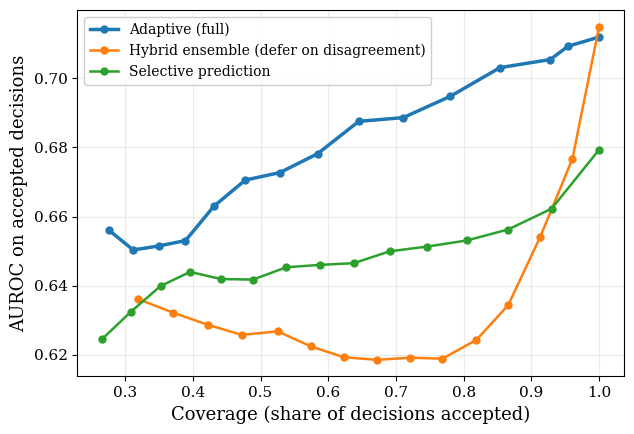

In [72]:
# Combined uncertainty: noise 20%, extra missingness 40%, sensor dropout 30%
#curves_unc = rc_curves(perturb(rawB, 0.2, 0.4, 0.3, seed=N_SEEDS - 1, stds=stds))

fig, ax = plt.subplots(figsize=(6.5, 4.5))

for m, pts in curves_unc.items():
    pts = sorted(pts)
    ax.plot(
        [a for a, _ in pts],
        [b for _, b in pts],
        marker="o",
        markersize=5,
        linewidth=2.5 if m == "Adaptive (full)" else 1.8,
        label=m
    )

ax.set_xlabel("Coverage (share of decisions accepted)", fontsize=13)
ax.set_ylabel("AUROC on accepted decisions", fontsize=13)
ax.tick_params(axis="both", labelsize=11)
ax.grid(alpha=0.25)
ax.legend(fontsize=10, loc="best", frameon=True, framealpha=0.95)
fig.tight_layout()

fig.savefig(f"{OUT_DIR}/fig10b_risk_coverage_uncertainty.png", dpi=600, bbox_inches="tight")
fig.savefig(f"{OUT_DIR}/fig10b_risk_coverage_uncertainty.pdf", bbox_inches="tight")
plt.show()

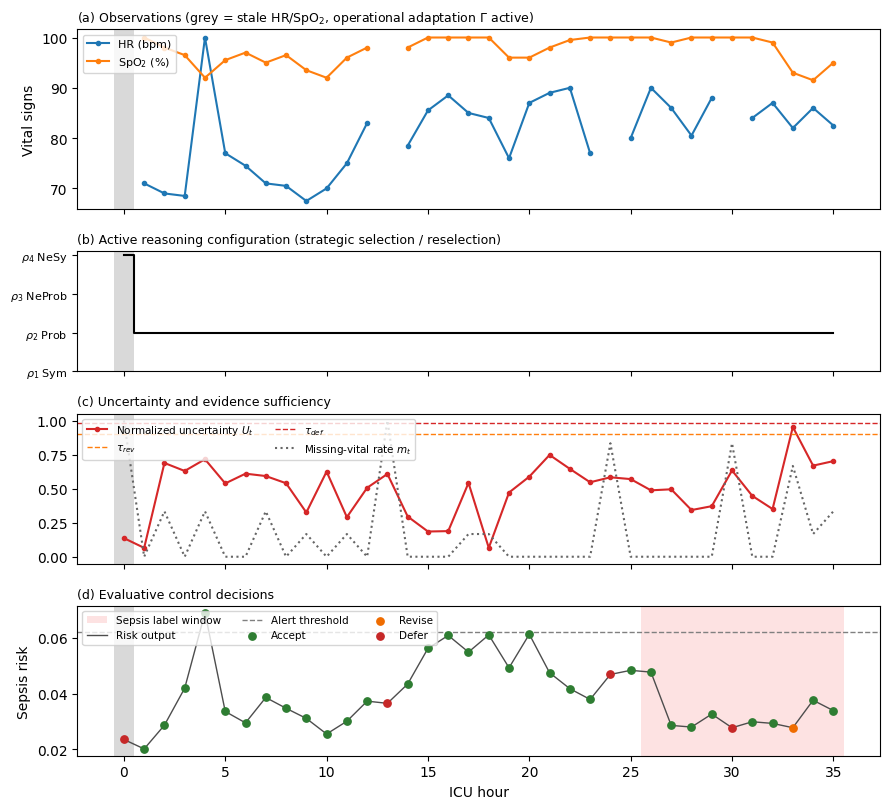

patient: p100047 | decisions: {'accept': np.int64(31), 'defer': np.int64(4), 'revise': np.int64(1)}


In [17]:
# ===== Fig. 11: Temporal evolution of reasoning configuration and control decisions =====
rb_t = perturb(rawB, 0, 0, 0.3, seed=0, stds=stds)            # sensor-dropout condition
Fb_t, _ = build_features(rb_t, med)
pb_t, _ = cfg.predict_all(Fb_t); pbm_t, _ = cfg.predict_all(mask_stale(Fb_t, med))
mc_t = MetaController(**params).calibrate(pv, Fva, yv, cost)
pf_t, dec_t, sel_t = mc_t.run(pb_t, pbm_t, Fb_t, rb_t.pid.values)
n = len(Fb_t)
U_t = np.column_stack([mc_t.unorm(c, pb_t[c]["u"]) for c in CONFIGS])[np.arange(n), sel_t]
active = np.where(dec_t == "reselect", 3, sel_t)                # reselection switches to rho4
stale = stale_mask(Fb_t)

# pick an informative septic patient: dropout present and several decision types
best, best_score = None, -1
for pid, idx in rb_t.groupby("pid").indices.items():
    if len(idx) < 30 or len(idx) > 90 or rb_t.SepsisLabel.values[idx].sum() == 0: continue
    score = len(set(dec_t[idx])) + 0.5 * stale[idx].any() + 0.2 * len(set(active[idx]))
    if score > best_score: best, best_score = idx, score
idx = best; h = np.arange(len(idx))

fig, ax = plt.subplots(4, 1, figsize=(9, 8.2), sharex=True, gridspec_kw={"height_ratios": [1.2, 0.8, 1, 1]})
# (a) vital signs and sensor dropout
ax[0].plot(h, rb_t.HR.values[idx], ".-", label="HR (bpm)")
ax[0].plot(h, rb_t.O2Sat.values[idx], ".-", label="SpO$_2$ (%)")
for a in ax: [a.axvspan(i - 0.5, i + 0.5, color="0.85", lw=0) for i in h[stale[idx]]]
ax[0].set_ylabel("Vital signs"); ax[0].legend(fontsize=8, loc="upper left")
ax[0].set_title("(a) Observations (grey = stale HR/SpO$_2$, operational adaptation $\\Gamma$ active)", fontsize=9, loc="left")
# (b) active reasoning configuration
ax[1].step(h, active[idx] + 1, where="mid", color="k")
ax[1].set_yticks([1, 2, 3, 4]); ax[1].set_yticklabels(["$\\rho_1$ Sym", "$\\rho_2$ Prob", "$\\rho_3$ NeProb", "$\\rho_4$ NeSy"], fontsize=8)
ax[1].set_title("(b) Active reasoning configuration (strategic selection / reselection)", fontsize=9, loc="left")
# (c) uncertainty and thresholds
ax[2].plot(h, U_t[idx], ".-", color="C3", label="Normalized uncertainty $U_t$")
ax[2].axhline(params["tau_rev"], ls="--", color="C1", lw=1, label="$\\tau_{rev}$")
ax[2].axhline(params["tau_def"], ls="--", color="C3", lw=1, label="$\\tau_{def}$")
ax[2].plot(h, Fb_t["miss_rate"].values[idx], ":", color="0.4", label="Missing-vital rate $m_t$")
ax[2].set_ylim(-0.05, 1.05); ax[2].legend(fontsize=7.5, loc="upper left", ncol=2)
ax[2].set_title("(c) Uncertainty and evidence sufficiency", fontsize=9, loc="left")
# (d) risk output and control decisions
lab = rb_t.SepsisLabel.values[idx]
if lab.any(): ax[3].axvspan(h[lab == 1][0] - 0.5, h[-1] + 0.5, color="#fde2e2", lw=0, label="Sepsis label window")
ax[3].plot(h, pf_t[idx], "-", color="0.3", lw=1, label="Risk output")
ax[3].axhline(th_meta, ls="--", color="0.5", lw=1, label="Alert threshold")
cols = {"accept": "#2e7d32", "revise": "#ef6c00", "reselect": "#6a1b9a", "defer": "#c62828"}
for d, c in cols.items():
    m = dec_t[idx] == d
    if m.any(): ax[3].scatter(h[m], pf_t[idx][m], color=c, s=28, zorder=3, label=d.capitalize())
ax[3].set_ylabel("Sepsis risk"); ax[3].set_xlabel("ICU hour")
ax[3].legend(fontsize=7.5, loc="upper left", ncol=3)
ax[3].set_title("(d) Evaluative control decisions", fontsize=9, loc="left")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/fig11_temporal_control.png", dpi=600, bbox_inches="tight")
fig.savefig(f"{OUT_DIR}/fig11_temporal_control.pdf", bbox_inches="tight"); plt.show()
print("patient:", rb_t.pid.values[idx][0], "| decisions:", dict(zip(*np.unique(dec_t[idx], return_counts=True))))

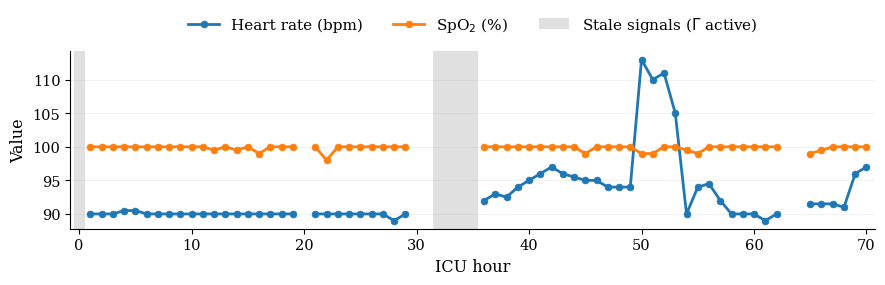

In [80]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# Selected patient
assert idx is not None, "No patient selected."

h = np.arange(len(idx))
hr = rb_t["HR"].to_numpy()[idx]
spo2 = rb_t["O2Sat"].to_numpy()[idx]

fig, a = plt.subplots(figsize=(9.0, 3.0))

# Stale-signal shading
for i in h[stale[idx]]:
    a.axvspan(i - 0.5, i + 0.5,
              color="0.88", lw=0, zorder=0)

# Vital signs
a.plot(h, hr, "-o", lw=2,
    markersize=5,
    markeredgewidth=0.4,
       color="#1f77b4", label="Heart rate (bpm)")

a.plot(h, spo2, "-o", lw=2,     markersize=5,
    markeredgewidth=0.4,
       color="#ff7f0e", label=r"SpO$_2$ (%)")

# Axes
a.set_xlim(h[0] - 0.8, h[-1] + 0.8)
a.set_xlabel("ICU hour")
a.set_ylabel("Value")
a.xaxis.set_major_locator(plt.MultipleLocator(10))
a.grid(axis="y", alpha=0.25, lw=0.5)
a.set_axisbelow(True)
a.spines[["top", "right"]].set_visible(False)

# Legend
handles, labels = a.get_legend_handles_labels()
handles.append(Patch(facecolor="0.88",
                     label=r"Stale signals ($\Gamma$ active)"))
labels.append(r"Stale signals ($\Gamma$ active)")

a.legend(handles, labels,
         loc="lower center",
         bbox_to_anchor=(0.5, 1.02),
         ncol=3, fontsize=11,
         frameon=False)

fig.tight_layout()

# Save
fig.savefig(f"{OUT_DIR}/fig11_vital_signs.pdf",
            bbox_inches="tight")
fig.savefig(f"{OUT_DIR}/fig11_vital_signs.png",
            dpi=600, bbox_inches="tight")

# Explicitly display in notebook
display(fig)
plt.close(fig)


In [68]:

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 11,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})


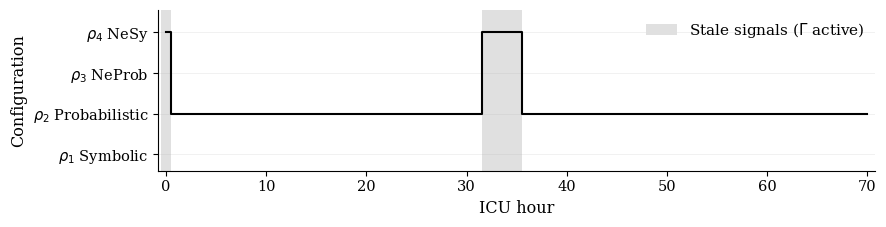

In [79]:

from matplotlib.patches import Patch

fig, a = plt.subplots(figsize=(9.0, 2.4))

# Stale-signal shading
for i in h[stale[idx]]:
    a.axvspan(i - 0.5, i + 0.5,
              color="0.88", lw=0, zorder=0)

# Active reasoning configuration
a.step(h, active[idx] + 1,
       where="mid", color="k", lw=1.5)

# Y-axis
a.set_yticks([1, 2, 3, 4])
a.set_yticklabels([
    r"$\rho_1$ Symbolic",
    r"$\rho_2$ Probabilistic",
    r"$\rho_3$ NeProb",
    r"$\rho_4$ NeSy"
])
a.set_ylim(0.6, 4.55)

# Axes formatting
a.set_xlim(h[0] - 0.8, h[-1] + 0.8)
a.set_xlabel("ICU hour", fontsize=11.5)
a.set_ylabel("Configuration", fontsize=11.5)

a.tick_params(axis="both", labelsize=10.5)
a.xaxis.set_major_locator(plt.MultipleLocator(10))

a.grid(axis="y", alpha=0.25, lw=0.5)
a.set_axisbelow(True)
a.spines[["top", "right"]].set_visible(False)

# Legend INSIDE axes
stale_patch = Patch(
    facecolor="0.88",
    label=r"Stale signals ($\Gamma$ active)"
)

a.legend(
    handles=[stale_patch],
    loc="upper right",
    fontsize=11,
    frameon=False,
    borderaxespad=0.3
)

fig.tight_layout()

fig.savefig(f"{OUT_DIR}/fig11b_configuration.png",
            dpi=600, bbox_inches="tight")
fig.savefig(f"{OUT_DIR}/fig11b_configuration.pdf",
            bbox_inches="tight")

plt.show()


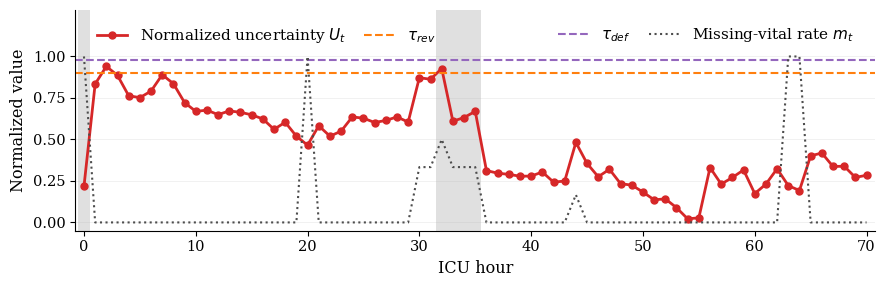

In [86]:
fig, a = plt.subplots(figsize=(9, 3.0))

# Stale-signal shading
for i in h[stale[idx]]:
    a.axvspan(i - 0.5, i + 0.5, color="0.88", lw=0, zorder=0)

# Lines
l1, = a.plot(h, U_t[idx], "-o",
             color="#d62728", lw=2, markersize=5,
             label=r"Normalized uncertainty $U_t$")

l2 = a.axhline(params["tau_rev"], ls="--",
               color="#ff7f0e", lw=1.5,
               label=r"$\tau_{rev}$")

l3 = a.axhline(params["tau_def"], ls="--",
               color="#9467bd", lw=1.5,
               label=r"$\tau_{def}$")

l4, = a.plot(h, Fb_t["miss_rate"].values[idx], ":",
             color="0.3", lw=1.5,
             label=r"Missing-vital rate $m_t$")

# Axes
a.set_ylim(-0.05, 1.28)
a.set_xlim(h[0] - 0.8, h[-1] + 0.8)
a.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
a.set_xlabel("ICU hour")
a.set_ylabel("Normalized value")
a.xaxis.set_major_locator(plt.MultipleLocator(10))
a.grid(axis="y", alpha=0.25, lw=0.5)
a.set_axisbelow(True)
a.spines[["top", "right"]].set_visible(False)

# Left legend
leg1 = a.legend(
    handles=[l1, l2],
    loc="upper left",
    bbox_to_anchor=(0.01, 0.99),
    ncol=2,
    frameon=False,
    fontsize=11,
    columnspacing=1.2,
    handlelength=2.0
)

# Right legend
leg2 = a.legend(
    handles=[l3, l4],
    loc="upper right",
    bbox_to_anchor=(0.99, 0.99),
    ncol=2,
    frameon=False,
    fontsize=11,
    columnspacing=1.2,
    handlelength=2.0
)

# Keep both legends
a.add_artist(leg1)

fig.tight_layout()
plt.show()

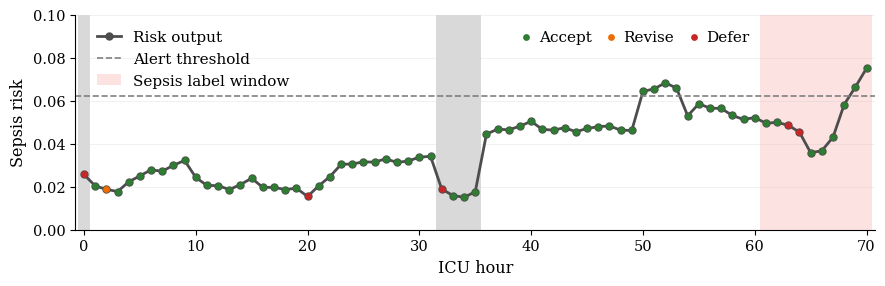

In [90]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, a = plt.subplots(figsize=(9, 3.0))

# Sepsis label window
lab = rb_t.SepsisLabel.values[idx]
if lab.any():
    a.axvspan(
        h[lab == 1][0] - 0.5, h[-1] + 0.5,
        color="#fde2e2", lw=0, zorder=0
    )

# Stale-signal shading
for i in h[stale[idx]]:
    a.axvspan(
        i - 0.5, i + 0.5,
        color="0.85", lw=0, zorder=1
    )

# Risk output: line with small circles
l1, = a.plot(
    h, pf_t[idx], "-o",
    color="0.3", lw=2,
    markersize=5,
    label="Risk output",
    zorder=2
)

# Alert threshold
l2 = a.axhline(
    th_meta, ls="--",
    color="0.5", lw=1.2,
    label="Alert threshold"
)

# Evaluative control decisions
cols = {
    "accept": "#2e7d32",
    "revise": "#ef6c00",
    "reselect": "#6a1b9a",
    "defer": "#c62828"
}

decision_handles = []

for dname, c in cols.items():
    m = dec_t[idx] == dname
    if m.any():
        sc = a.scatter(
            h[m], pf_t[idx][m],
            color=c, s=15,
            zorder=4,
            label=dname.capitalize()
        )
        decision_handles.append(sc)

# Axes
a.set_ylim(-0.03, 1.28)
a.set_xlim(h[0] - 0.8, h[-1] + 0.8)
a.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

a.set_ylabel("Sepsis risk")
a.set_xlabel("ICU hour")
a.xaxis.set_major_locator(plt.MultipleLocator(10))
a.set_ylim(0, 0.1)
a.set_yticks(np.arange(0, 0.101, 0.02))
a.grid(axis="y", alpha=0.25, lw=0.5)
a.set_axisbelow(True)
a.spines[["top", "right"]].set_visible(False)

# Left legend: risk, threshold, sepsis window
sepsis_patch = Patch(
    facecolor="#fde2e2",
    label="Sepsis label window"
)

left_handles = [l1, l2]
if lab.any():
    left_handles.append(sepsis_patch)

leg1 = a.legend(
    handles=left_handles,
    loc="upper left",
    bbox_to_anchor=(0.01, 0.99),
    ncol=1,
    fontsize=11,
    frameon=False,
    columnspacing=1.0,
    handlelength=1.6
)

# Right legend: all four decisions in one row
leg2 = a.legend(
    handles=decision_handles,
    loc="upper right",
    bbox_to_anchor=(0.86, 0.99),
    ncol=3,
    fontsize=11,
    frameon=False,
    columnspacing=0.8,
    handletextpad=0.3,
    handlelength=1.0
)

a.add_artist(leg1)

fig.tight_layout()

fig.savefig(
    f"{OUT_DIR}/fig11d_decisions.png",
    dpi=600, bbox_inches="tight"
)

fig.savefig(
    f"{OUT_DIR}/fig11d_decisions.pdf",
    bbox_inches="tight"
)

plt.show()


### Package results

In [19]:
import shutil
shutil.make_archive("simulation_results", "zip", OUT_DIR)
print("Saved: simulation_results.zip  (tables .tex, figures .pdf/.png, raw results .csv)")

Saved: simulation_results.zip  (tables .tex, figures .pdf/.png, raw results .csv)
